In [1]:
import cv2
from PIL import Image
import os
import os.path
import numpy as np
import torch
import torch.nn.functional as F
from torchinfo import summary
import pickle as pkl
import imageio.v2 as imageio
import torch
# 
from core.models.resnet  import resnet101
from core.models import build_feature_extractor, build_classifier
from core.configs import cfg
import scipy.io as io

In [2]:
cfg.merge_from_file('configs/synthia/deeplabv2_r101_src.yaml')

In [3]:
cfg.freeze()

In [4]:
NUM_CLASSES = {"S": 16, "D": 1}
TASKNAMES = ["S", "D"]

In [5]:
from core.models.resnet  import resnet101
from core.models import build_feature_extractor, build_classifier
from core.configs import cfg

In [6]:
feature = build_feature_extractor(cfg)
classifier = build_classifier(cfg, TASKNAMES, NUM_CLASSES)

Loads checkpoint by http backend from path: https://download.pytorch.org/models/resnet101-5d3b4d8f.pth


In [7]:
a = torch.randn(2,3,640,360)

In [8]:
out = feature(a)

In [ ]:
out

In [10]:
out['D'].shape

torch.Size([2, 2048, 80, 45])

In [ ]:
a = torch.randn(2,2048,80,45)
b = torch.randn(2,2048,80,45)



In [13]:
c = torch.randn(2,2,2,2)
d = torch.randn(1,2,2,2,2)
f = torch.stack([v for v in d],dim=0)
e = torch.sum(f,dim=0)
e.shape

torch.Size([2, 2, 2, 2])

In [ ]:
c = torch.cat((a,b),dim = 1)
d = torch.add(a,b)
c.shape
d.shape

In [ ]:
classifier['D'](out['T'])

In [9]:
from torchview import draw_graph

In [10]:
model_graph4 = draw_graph(feature,a)
model_graph4.resize_graph(1)

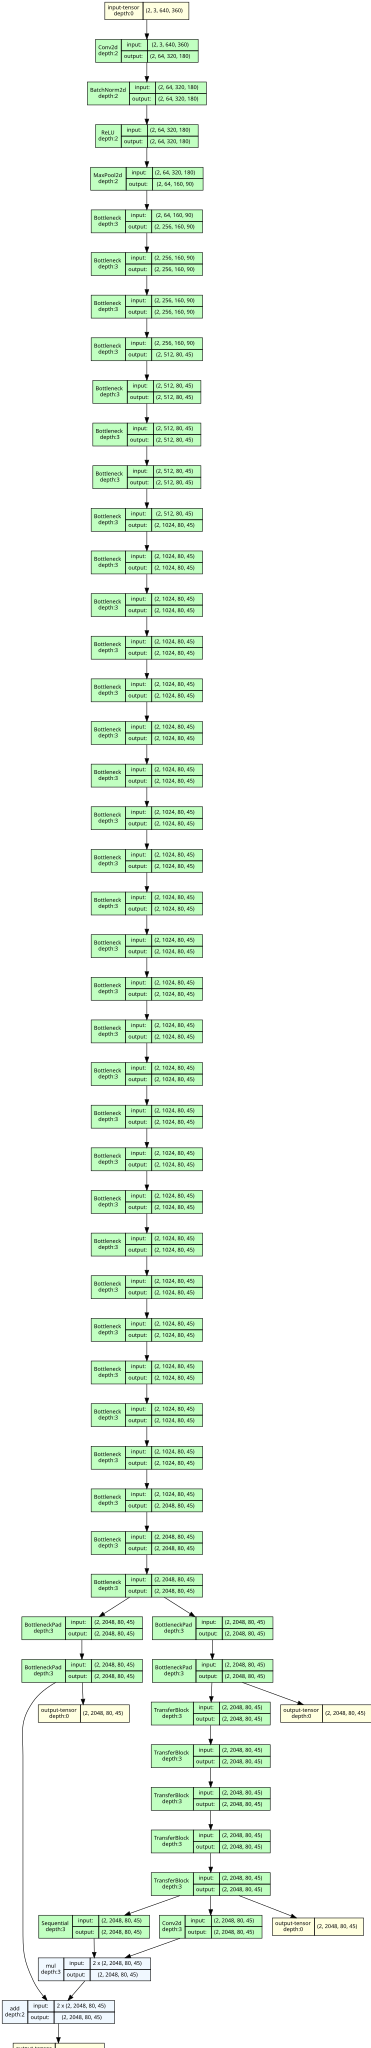

In [11]:
model_graph4.visual_graph


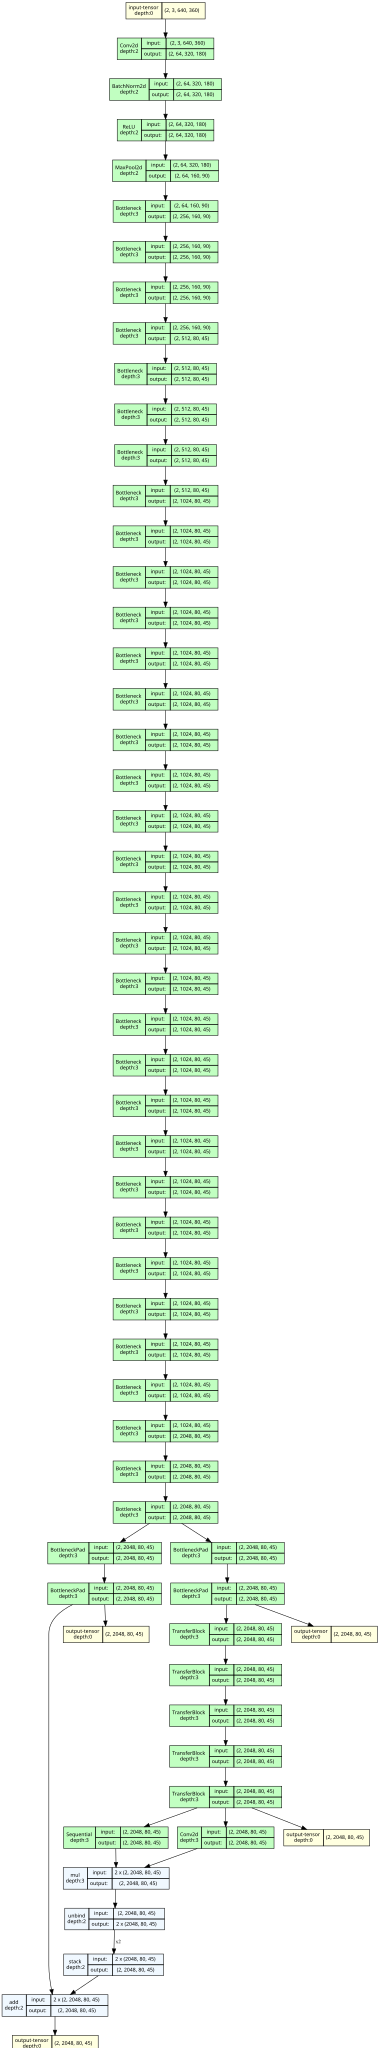

In [10]:
model_graph3 = draw_graph(feature,a)
model_graph3.resize_graph(1)
model_graph3.visual_graph

In [ ]:
model_graph2 = draw_graph(feature,a)
model_graph2.resize_graph(2)

In [ ]:
model_graph2.visual_graph

In [ ]:
model_graph1 = draw_graph(feature,a)
model_graph1.resize_graph(2)

In [ ]:
model_graph1.visual_graph

In [ ]:
model_graph = draw_graph(feature,a)
model_graph.resize_graph(2)

In [ ]:
model_graph.visual_graph

In [ ]:
model_graph = draw_graph(classifier['D'],out['D'])

In [ ]:
model_graph.visual_graph

In [ ]:
datapath = '/home/dauphin/Documents/Project/ProCA/datasets/synthia/RAND_CITYSCAPES/GT/LABELS'


In [ ]:
empty = {}
cnt = 0
for dirpath, dirnames, filenames in os.walk(datapath):
    for filename in [f for f in filenames if f.endswith(".png")]:
        # fname = os.path.join(dirpath,filename)
        # img = np.array(Image.open(fname), dtype=np.float32)
        # if len(np.unique(img, return_counts=True)[0]) <= 1:
        #     empty[fname] = np.unique(img, return_counts=True)
        cnt+=1

In [ ]:
np.unique(np.asarray(Image.open('datasets/synthia/RAND_CITYSCAPES/GT/LABELS/0000006.png'))[:, :, 1])

In [ ]:
imageio.imread('datasets/synthia/RAND_CITYSCAPES/GT/LABELS/0000006.png', format='PNG')

In [ ]:
empty

In [ ]:
path = '/home/dauphin/Documents/Project/ProCA/datasets/cityscapes/gtFine/train/jena/jena_000020_000019_gtFine_labelIds.png'
img = np.array(Image.open(path), dtype=np.float32)
np.unique(img, return_counts=True)[0]
img.shape

In [ ]:
src = open('datasets/cityscapes_train_list.txt', 'r').readlines()
target = open('datasets/synthia_train_list.txt', 'r').readlines()


In [ ]:
src2 = []
target2 = []

for temp in  target:
    target2.append(temp.strip())


for temp in  src:
    src2.append(temp.strip())     

In [ ]:
img1 = torch.rand((1,3,640,360))
img1.shape
img2  = F.interpolate(img1, size=[640,360], mode='bilinear', align_corners=True)
img2.shape

In [ ]:
torch.equal(img1,img2)

In [ ]:
label_to_file,file_to_label = pkl.load(open('datasets/synthia/synthia_label_info_working.p', 'rb'))
# f_not = pkl.load(open('datasets/synthia/synthia_label_info_not.p', 'rb'))
# f_check = pkl.load(open('datasets/synthia/synthia_label_info.p', 'rb'))

In [ ]:
path = 'datasets/synthia/RAND_CITYSCAPES/Depth/Depth/0007212.png'
label_pth = 'datasets/synthia/RAND_CITYSCAPES/synthia_mapped_to_cityscapes/0007212.png'

In [ ]:
depth = np.array(cv2.imread(path, flags=cv2.IMREAD_ANYDEPTH), dtype=np.float32)
depth.shape

In [ ]:
depth = 'datasets/cityscapes/depth/train/aachen/aachen_000000_000019_depth_stereoscopic.mat'

In [ ]:
name = 'aachen/aachen_000000_000019_leftImg8bit.png'
name.split("_leftImg8bit")[0] + "_depth_stereoscopic.mat"

In [ ]:
depth_map = io.loadmat(depth)["depth_map"] 

In [ ]:
depth_map.dtype

In [ ]:
depth_map = np.clip(depth_map, 0., 655.35)


In [ ]:
depth_map[depth_map<0.1] = 655.35


In [ ]:
# depth_map = 655.36 / (depth_map + 0.01)
depth_map.dtype

In [ ]:
type(depth_map)

In [ ]:
depth_map = depth_map.astype(np.float32)

In [ ]:
depth

In [ ]:
type(depth_map)
depth_map.dtype

In [ ]:
depth_base =  os.path.join('datasets/cityscapes/', "depth", 'train')

In [ ]:
depth_base